In [ ]:
import pandas as pd
import numpy as np


df = pd.read_csv("zomato.csv")


df.head()

,Unnamed: 0.1,Unnamed: 0,restaurant name,restaurant type,rate (out of 5),num of ratings,avg cost (two people),online_order,table booking,cuisines type,area,local address
0,0,0,#FeelTheROLL,Quick Bites,3.4,7,200.0,No,No,Fast Food,Bellandur,Bellandur
1,1,1,#L-81 Cafe,Quick Bites,3.9,48,400.0,Yes,No,"Fast Food, Beverages","Byresandra,Tavarekere,Madiwala",HSR
2,2,2,#refuel,Cafe,3.7,37,400.0,Yes,No,"Cafe, Beverages",Bannerghatta Road,Bannerghatta Road
3,3,3,'@ Biryani Central,Casual Dining,2.7,135,550.0,Yes,No,"Biryani, Mughlai, Chinese",Marathahalli,Marathahalli
4,4,4,'@ The Bbq,Casual Dining,2.8,40,700.0,Yes,No,"BBQ, Continental, North Indian, Chinese, Bever...",Bellandur,Bellandur


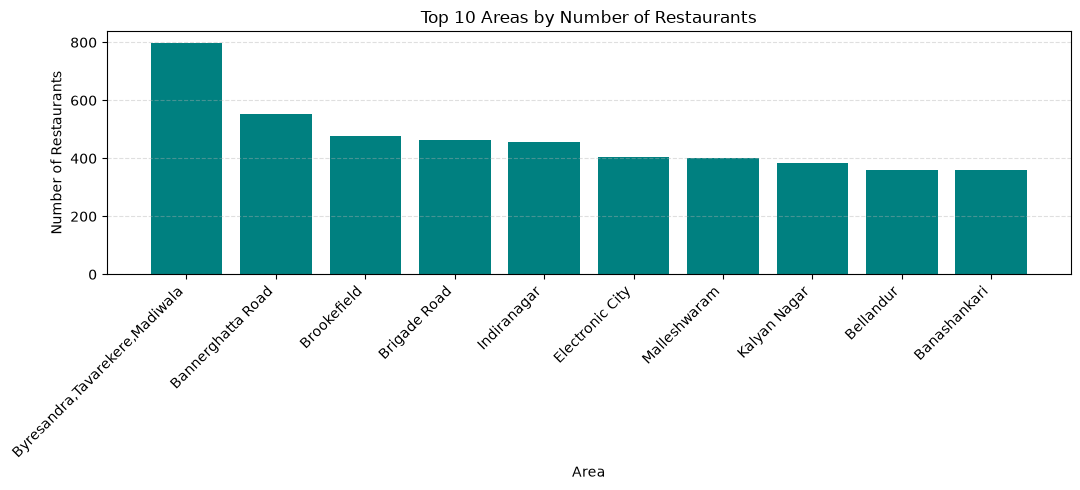

In [8]:
restaurants_by_area = df['area'].value_counts()

import matplotlib.pyplot as plt

top_10_areas = restaurants_by_area.head(10)
plt.figure(figsize=(11, 5))
plt.bar(top_10_areas.index, top_10_areas.values, color='teal')
plt.xlabel('Area')
plt.ylabel('Number of Restaurants')
plt.title('Top 10 Areas by Number of Restaurants')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

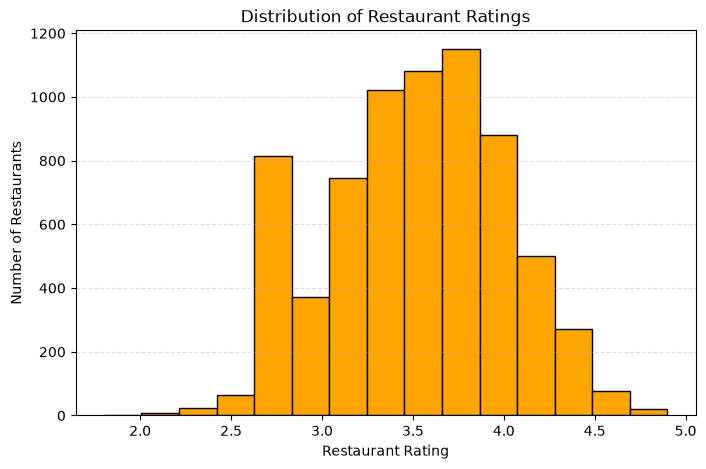

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df['rate (out of 5)'], bins=15, color='orange', edgecolor='black')
plt.xlabel('Restaurant Rating')
plt.ylabel('Number of Restaurants')
plt.title('Distribution of Restaurant Ratings')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

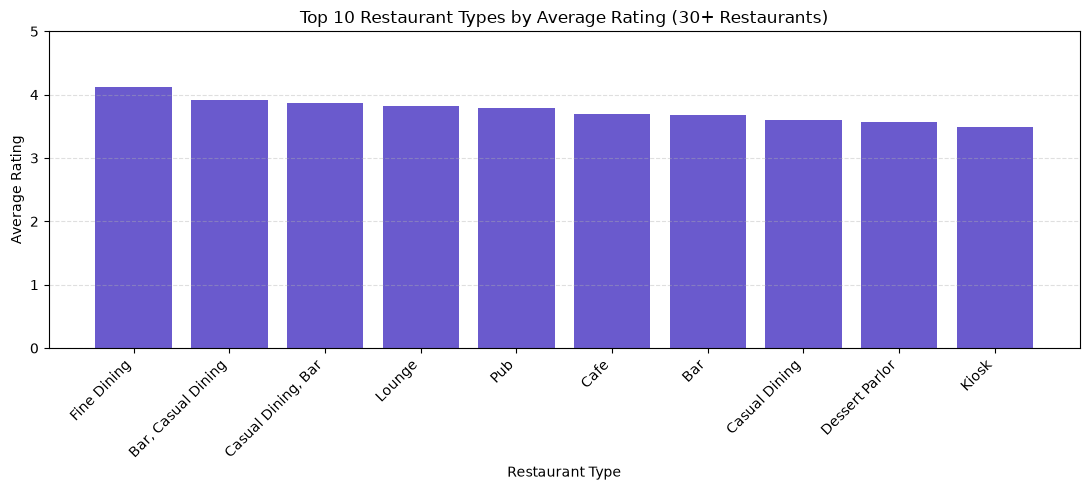

In [12]:
restaurant_type_insights_30 = (
    df.groupby('restaurant type')
      .agg(
          restaurant_count=('restaurant name', 'count'),
          average_rating=('rate (out of 5)', 'mean')
      )
      .query('restaurant_count >= 30')
)

top_rated_types = restaurant_type_insights_30.sort_values(
    'average_rating', ascending=False
).head(10)

plt.figure(figsize=(11, 5))
plt.bar(top_rated_types.index, top_rated_types['average_rating'], color='slateblue')
plt.xlabel('Restaurant Type')
plt.ylabel('Average Rating')
plt.title('Top 10 Restaurant Types by Average Rating (30+ Restaurants)')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 5)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

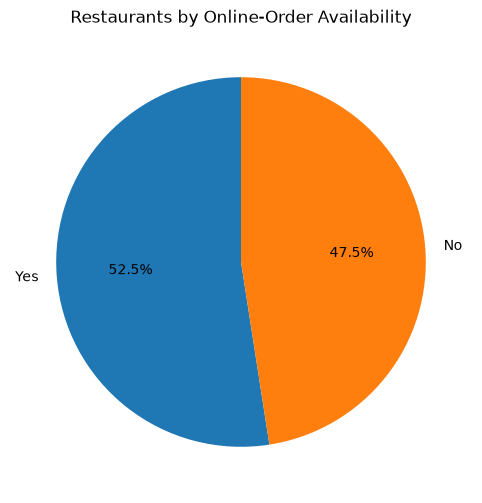

In [14]:
online_order_counts = df['online_order'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    online_order_counts.values,
    labels=online_order_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    shadow=False
)
plt.title('Restaurants by Online-Order Availability')
plt.show()

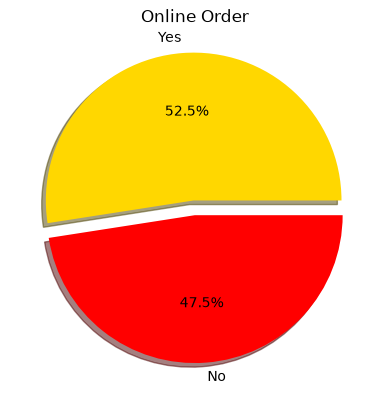

In [20]:
online = df['online_order'].value_counts()

plt.pie(online.values,labels=online.index,colors=['gold','red'],autopct='%1.1f%%',explode=(0.1,0),shadow=True)
plt.title('Online Order')
plt.show()

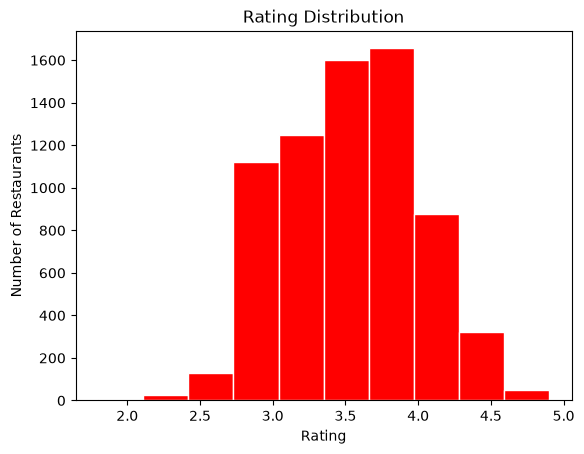

In [22]:
plt.hist(df['rate (out of 5)'], bins=10, color='red', edgecolor='white')
plt.xlabel('Rating')
plt.ylabel('Number of Restaurants')
plt.title('Rating Distribution')
plt.show()

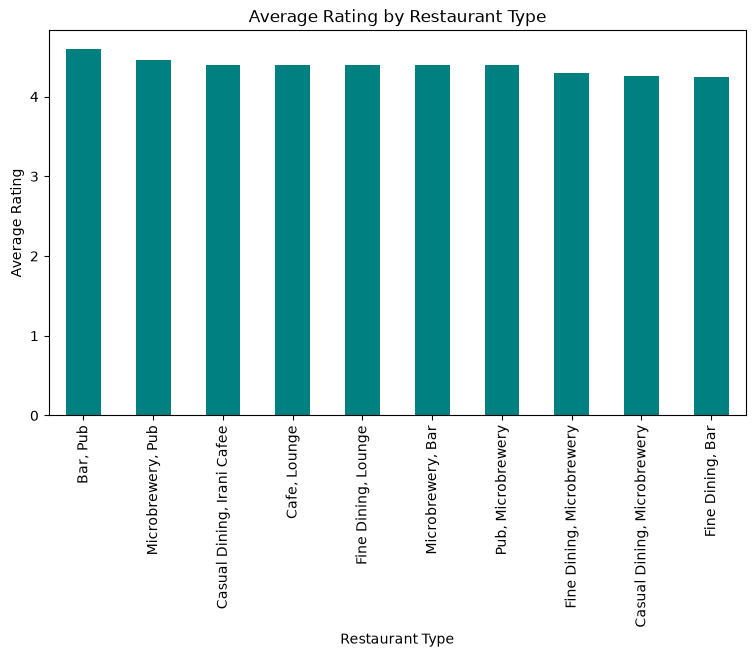

In [24]:
avg_rating = (
    df.groupby('restaurant type')['rate (out of 5)']
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

avg_rating.plot(kind='bar',color='teal',figsize=(9,5))
plt.xlabel('Restaurant Type')
plt.ylabel('Average Rating')
plt.title('Average Rating by Restaurant Type')
plt.show()

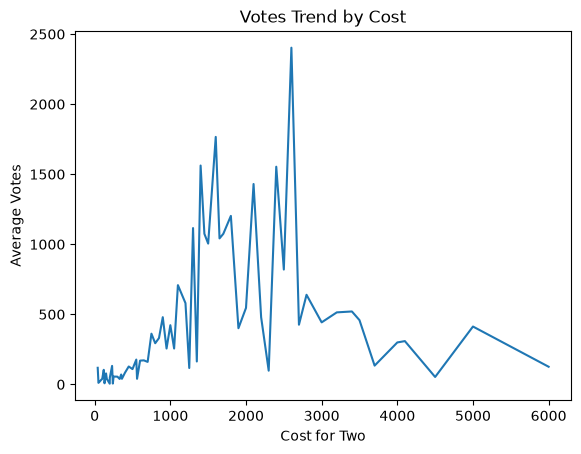

In [ ]:


cost_trend = (
    df.groupby('avg cost (two people)', as_index=False)['num of ratings']
      .mean()
      .rename(columns={
          'avg cost (two people)': 'cost',
          'num of ratings': 'votes'
      })
      .sort_values('cost')
)
plt.plot(cost_trend['cost'],cost_trend['votes'])
plt.xlabel('Cost for Two')
plt.ylabel('Average Votes')
plt.title('Votes Trend by Cost')
plt.show()